# Bước B1 (phần so sánh) - gom 3 lần huấn luyện B1 (Sequential Forecast LSTM có Q theo mm/ngày + qmax quá khứ, fork e794d7c sửa lưu mô hình tốt nhất; hạt giống 111, 222, 333), so với 3 lần huấn luyện lại A4 (cấu hình tác giả) và
 best_model.pt của tác giả BiasCast, đọc chênh lệch theo nhiễu hạt giống A4, xuất dự báo theo hợp đồng NPZ của bộ đánh giá
 Bài: Konold và cs., HESS 30:5067-5096 (2026). Kế hoạch: Document/01_Plan/03_Pipeline.md Mục 7 (dòng B1), 9.5.
 Notebook Kaggle "02_B1_LamaHCEExt_Compare": Accelerator = None (CPU), Internet = On, Persistence = Files only,
# Environment = Pin to original environment. Add Input:
   - Output 3 notebook 01_B1_LamaHCEExt_Train_Seed111 (Version 1), _Seed222 (Version 1), _Seed333 (Version 2);
   - Output 3 notebook 03_A4_LamaHCEExt_Retrain_Seed111 (Version 1), _Seed222 (Version 2), _Seed333 (Version 2);
   - Output 02_A3_LamaHCEExt_Benchmarks (người 1, Version 1) - ngữ cảnh quan trắc, persistence, diện tích;
  - Dataset lamah-ce-ext - chỉ số test của tác giả.
 Không cần GPU, không cần thư viện NeuralHydrology: test_results.p chỉ cần xarray để đọc (như 04_A4_LamaHCEExt_Compare).
 Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Tìm Input, kiểm sha256 tệp của 6 run, môi trường
   Phần 2 - Bảng 6 run và tác giả, chênh B1 - A4 theo nhiễu hạt giống, quy tắc lưu mô hình cũ và mới
   Phần 3 - So từng lưu vực B1 với A4, nhiễu hạt giống, kiểm định ghép cặp
   Phần 4 - Hình B1_Compare.png, B1_BasinDelta.png
   Phần 5 - Dựng NPZ hợp đồng bộ đánh giá cho 3 hạt giống B1 và kiểm lại
   Phần 6 - Lưu bảng, b1_summary.json, environment.json, manifest.csv

# Phần 1 - Tìm Input, kiểm sha256 tệp của 6 run, môi trường
 Mỗi notebook huấn luyện ghi <bước>_output/environment.json (hạt giống, thư mục run, commit thư viện, tóm tắt) và
 <bước>_output/manifest.csv (tệp chính của run kèm sha256, đường dẫn tính từ /kaggle/working của notebook đó): B1 8 tệp
 (01_B1_LamaHCEExt_Train_Seed111.py dòng 989-993, thêm chỉ số và dự báo validation của epoch best_model.pt), A4 6 tệp
 (03_A4_LamaHCEExt_Retrain_Seed111.py dòng 680). Tìm 6 thư mục đó trong Input theo environment.json (không theo tên đường
 dẫn), tính lại sha256 từng tệp để chắc Input gắn đúng bản lưu và không hỏng khi chép. Tìm thêm 2 tệp ngữ cảnh của A3
 (A3_persistence_predictions.npz, A3_Q_source_window.npz - tên theo 02_A3_LamaHCEExt_Benchmarks.py dòng 805, 964) và chỉ
 số test của tác giả (cùng run A2, A4, B1 dùng). Phần 1 chưa đạt thì dừng notebook.

In [1]:
# %% Phần 1 - Tìm Input, kiểm sha256 tệp của 6 run, môi trường
# Mỗi notebook huấn luyện ghi <bước>_output/environment.json (hạt giống, thư mục run, commit thư viện, tóm tắt) và
# <bước>_output/manifest.csv (tệp chính của run kèm sha256, đường dẫn tính từ /kaggle/working của notebook đó): B1 8 tệp
# (01_B1_LamaHCEExt_Train_Seed111.py dòng 989-993, thêm chỉ số và dự báo validation của epoch best_model.pt), A4 6 tệp
# (03_A4_LamaHCEExt_Retrain_Seed111.py dòng 680). Tìm 6 thư mục đó trong Input theo environment.json (không theo tên đường
# dẫn), tính lại sha256 từng tệp để chắc Input gắn đúng bản lưu và không hỏng khi chép. Tìm thêm 2 tệp ngữ cảnh của A3
# (A3_persistence_predictions.npz, A3_Q_source_window.npz - tên theo 02_A3_LamaHCEExt_Benchmarks.py dòng 805, 964) và chỉ
# số test của tác giả (cùng run A2, A4, B1 dùng). Phần 1 chưa đạt thì dừng notebook.
import hashlib
import json
import os
import platform
import re
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import HTML, display

IS_KAGGLE = Path("/kaggle/working").exists()
INPUT_ROOT = Path(os.environ.get("B1C_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "b1_compare_input"))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("b1_compare_work")
OUT_DIR = WORK_DIR / "b1_compare"
SEEDS = [111, 222, 333]
# Bản lưu chính thức trên Kaggle: B1 Save & Run All 24-25/10/2026, A4 23-24/10/2026
STEPS = {"B1": {"notebook": "01_B1_LamaHCEExt_Train_Seed{}", "out": "b1_output", "versions": {111: 1, 222: 1, 333: 2},
                "commit": "e794d7c2c0a5841a77145c632a3697cf7f1aa7ce", "n_files": 8},
         "A4": {"notebook": "03_A4_LamaHCEExt_Retrain_Seed{}", "out": "a4_output", "versions": {111: 1, 222: 2, 333: 2},
                "commit": "dda45fcf19ee7ffd481b9d192778539df46fb074", "n_files": 6}}
A3_VERSION = 1
A3_FILES = ["A3_persistence_predictions.npz", "A3_Q_source_window.npz"]
AUTHOR_METRICS_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                      "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/test/best_model/test_metrics.csv")
ENV_LIBS = ["numpy", "pandas", "xarray", "scipy", "matplotlib"]
OUT_DIR.mkdir(parents=True, exist_ok=True)


def show(title, df, digits=4):
    # Bảng HTML: số thực làm tròn `digits` chữ số, ô trống hiện "-".
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=digits, na_rep="-"))


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def short(path, keep=3):
    # Đường dẫn tính từ INPUT_ROOT, dài thì giữ 2 cấp đầu và `keep` cấp cuối.
    parts = Path(path).relative_to(INPUT_ROOT).parts
    return "/".join(parts) if len(parts) <= keep + 2 else "/".join(parts[:2] + ("...",) + parts[-keep:])


def unique_file(root, name):
    # Đúng một tệp tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều (gắn trùng Input).
    hits = sorted(root.rglob(name))
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 tệp '{name}' dưới {root}, thấy {len(hits)}: {hits}")
    return hits[0]


# (1) Thư mục output của 6 notebook huấn luyện: nhận theo environment.json, không theo tên đường dẫn
ROOTS, ENVS = {}, {}
for step, spec in STEPS.items():
    for env_path in sorted(INPUT_ROOT.rglob(f"{spec['out']}/environment.json")):
        env = json.loads(env_path.read_text(encoding="utf-8"))
        key = (step, env.get("seed"))
        if key in ROOTS:
            raise RuntimeError(f"{step} hạt giống {env.get('seed')} có ở 2 Input: {ROOTS[key]}, {env_path.parent.parent}")
        ROOTS[key], ENVS[key] = env_path.parent.parent, env  # thư mục tương ứng /kaggle/working của notebook đó
found = {step: sorted(s for st, s in ROOTS if st == step) for step in STEPS}
if any(found[step] != SEEDS for step in STEPS):
    raise RuntimeError(f"Cần Output của đúng 3 notebook hạt giống {SEEDS} mỗi bước, thấy {found} - kiểm Add Input")
RUNS = [(step, s) for step in STEPS for s in SEEDS]
show("Output 6 notebook huấn luyện", pd.DataFrame([{
    "bước": st, "hạt giống": s, "notebook": STEPS[st]["notebook"].format(s), "Version": STEPS[st]["versions"][s],
    "thư mục Input": short(ROOTS[st, s]), "thư mục run": ENVS[st, s]["run_dir"],
    "commit thư viện": ENVS[st, s]["neuralhydrology_commit"][:7], "GPU": ENVS[st, s]["gpu"],
    "torch": ENVS[st, s]["libs"]["torch"], "epoch best_model.pt": ENVS[st, s]["summary"]["saved_epoch"],
    "số epoch": ENVS[st, s]["summary"]["n_epochs"]} for st, s in RUNS]))

# (2) Kiểm sha256 từng tệp trong manifest.csv
rows = []
for st, s in RUNS:
    root = ROOTS[st, s]
    man = pd.read_csv(root / STEPS[st]["out"] / "manifest.csv")
    for rel, digest in zip(man["tệp"], man["sha256"]):
        f = root / rel
        got = sha256(f) if f.exists() else "THIẾU"
        # bỏ thư mục run, gộp model_epochXXX của epoch best_model.pt để 6 run cùng một dòng
        name = re.sub(r"model_epoch\d{3}", "model_epoch(best)", rel.split("/", 2)[-1])
        rows.append({"bước": st, "hạt giống": s, "tệp": name,
                     "KB": round(f.stat().st_size / 1e3, 1) if f.exists() else None,
                     "sha256 khớp": "ĐẠT" if got == digest else "KHÔNG"})
SHA_DF = pd.DataFrame(rows)
SHA_DF["run"] = SHA_DF["bước"] + " " + SHA_DF["hạt giống"].astype(str)
show("sha256 tệp chính của 6 run (so với manifest.csv của từng notebook; '-' là tệp run đó không ghi)",
     SHA_DF.pivot(index="tệp", columns="run", values="sha256 khớp")[[f"{st} {s}" for st, s in RUNS]].reset_index())

# (3) Ngữ cảnh A3 và chỉ số test của tác giả
A3_PATHS = {name: unique_file(INPUT_ROOT, name) for name in A3_FILES}
author_hits = [p for p in INPUT_ROOT.rglob("test_metrics.csv") if p.as_posix().endswith(AUTHOR_METRICS_REL)]
if len(author_hits) != 1:
    raise FileNotFoundError(f"Cần đúng 1 tệp chỉ số test của tác giả ({AUTHOR_METRICS_REL}), thấy {len(author_hits)} - gắn lamah-ce-ext")
AUTHOR_METRICS_PATH = author_hits[0]
show("Tệp ngữ cảnh", pd.DataFrame(
    [{"tệp": n, "đường dẫn": short(p), "KB": round(p.stat().st_size / 1e3, 1)} for n, p in A3_PATHS.items()]
    + [{"tệp": "test_metrics.csv của tác giả", "đường dẫn": short(AUTHOR_METRICS_PATH),
        "KB": round(AUTHOR_METRICS_PATH.stat().st_size / 1e3, 1)}]), digits=1)

# (4) Môi trường của notebook này
ENV = {"Python": platform.python_version(), **{lib: metadata.version(lib) for lib in ENV_LIBS},
       "Số CPU": os.cpu_count(), "Ngày dựng ảnh Kaggle":
       Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"}
show("Môi trường", pd.DataFrame({"mục": list(ENV), "giá trị": [str(v) for v in ENV.values()]}))

n_files = SHA_DF.groupby(["bước", "hạt giống"]).size()
checks = [("Đủ 3 hạt giống mỗi bước", found, {st: SEEDS for st in STEPS}, all(found[st] == SEEDS for st in STEPS))]
for st, spec in STEPS.items():
    commits = sorted({ENVS[st, s]["neuralhydrology_commit"][:7] for s in SEEDS})
    checks += [(f"{st}: mỗi hạt giống đủ {spec['n_files']} tệp chính", n_files[st].to_dict(), f"{spec['n_files']} mỗi hạt giống",
                n_files[st].eq(spec["n_files"]).all()),
               (f"{st}: commit thư viện {spec['commit'][:7]}", commits, spec["commit"][:7],
                all(ENVS[st, s]["neuralhydrology_commit"] == spec["commit"] for s in SEEDS))]
checks += [("sha256 khớp manifest", f"{int((SHA_DF['sha256 khớp'] == 'ĐẠT').sum())} / {len(SHA_DF)}", "tất cả",
            (SHA_DF["sha256 khớp"] == "ĐẠT").all()),
           ("Cùng phiên bản torch ở 6 run", sorted({ENVS[k]["libs"]["torch"] for k in RUNS}), "1 bản",
            len({ENVS[k]["libs"]["torch"] for k in RUNS}) == 1)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
if not all(c[3] for c in checks):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở trên) - kiểm Input rồi chạy lại")
print("=> Đạt. Chạy Phần 2.")


bước,hạt giống,notebook,Version,thư mục Input,thư mục run,commit thư viện,GPU,torch,epoch best_model.pt,số epoch
B1,111,01_B1_LamaHCEExt_Train_Seed111,1,notebooks/hunhngcthng/01-b1-lamahceext-train-seed111,b1_runs/B1_SeqLSTM_Q_seed111_2410_142912,e794d7c,Tesla T4,2.11.0+cu128,10,10
B1,222,01_B1_LamaHCEExt_Train_Seed222,1,notebooks/hunhngcthng/01-b1-lamahceext-train-seed222,b1_runs/B1_SeqLSTM_Q_seed222_2410_143830,e794d7c,Tesla T4,2.11.0+cu128,8,13
B1,333,01_B1_LamaHCEExt_Train_Seed333,2,notebooks/hunhngcthng/01-b1-lamahceext-train-seed333,b1_runs/B1_SeqLSTM_Q_seed333_2410_170509,e794d7c,Tesla T4,2.11.0+cu128,3,8
A4,111,03_A4_LamaHCEExt_Retrain_Seed111,1,notebooks/hunhngcthng/03-a4-lamahceext-retrain-seed111,a4_runs/A4_SeqLSTM_Q_seed111_2310_193149,dda45fc,Tesla T4,2.11.0+cu128,11,16
A4,222,03_A4_LamaHCEExt_Retrain_Seed222,2,notebooks/hunhngcthng/03-a4-lamahceext-retrain-seed222,a4_runs/A4_SeqLSTM_Q_seed222_2310_194052,dda45fc,Tesla T4,2.11.0+cu128,15,20
A4,333,03_A4_LamaHCEExt_Retrain_Seed333,2,notebooks/hunhngcthng/03-a4-lamahceext-retrain-seed333,a4_runs/A4_SeqLSTM_Q_seed333_2310_232038,dda45fc,Tesla T4,2.11.0+cu128,14,19


tệp,B1 111,B1 222,B1 333,A4 111,A4 222,A4 333
best_model.pt,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
config.yml,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
output.log,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_metrics.csv,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_results.p,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
train_data/train_data_scaler.yml,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
validation/model_epoch(best)/validation_metrics.csv,ĐẠT,ĐẠT,ĐẠT,-,-,-
validation/model_epoch(best)/validation_results.p,ĐẠT,ĐẠT,ĐẠT,-,-,-


tệp,đường dẫn,KB
A3_persistence_predictions.npz,notebooks/hunhthanhnhn/02-a3-lamahceext-benchmarks/a3_output/A3_persistence_predictions.npz,8136.7
A3_Q_source_window.npz,notebooks/hunhthanhnhn/02-a3-lamahceext-benchmarks/a3_output/A3_Q_source_window.npz,3349.0
test_metrics.csv của tác giả,datasets/hunhngcthng/.../test/best_model/test_metrics.csv,18.8


mục,giá trị
Python,3.13.15
numpy,2.1.3
pandas,2.3.3
xarray,2025.12.0
scipy,1.16.3
matplotlib,3.10.0
Số CPU,4
Ngày dựng ảnh Kaggle,20261022-041801


mục,giá trị,cần,đạt
Đủ 3 hạt giống mỗi bước,"{'B1': [111, 222, 333], 'A4': [111, 222, 333]}","{'B1': [111, 222, 333], 'A4': [111, 222, 333]}",ĐẠT
B1: mỗi hạt giống đủ 8 tệp chính,"{111: 8, 222: 8, 333: 8}",8 mỗi hạt giống,ĐẠT
B1: commit thư viện e794d7c,['e794d7c'],e794d7c,ĐẠT
A4: mỗi hạt giống đủ 6 tệp chính,"{111: 6, 222: 6, 333: 6}",6 mỗi hạt giống,ĐẠT
A4: commit thư viện dda45fc,['dda45fc'],dda45fc,ĐẠT
sha256 khớp manifest,42 / 42,tất cả,ĐẠT
Cùng phiên bản torch ở 6 run,['2.11.0+cu128'],1 bản,ĐẠT


=> Đạt. Chạy Phần 2.


# Phần 2 - Bảng 6 run và tác giả, chênh B1 - A4 theo nhiễu hạt giống, quy tắc lưu mô hình cũ và mới
 (1) Đọc NSE/KGE từng lưu vực của best_model.pt trên test (test/best_model/test_metrics.csv), NSE validation theo epoch
 (<bước>_output/validation_curve_seed{N}.csv), summary_seed{N}.json và config.yml của từng run (đã kiểm sha256 ở Phần 1);
 tính lại trung vị rồi đối chiếu summary.
 (2) Thống kê qua 3 hạt giống mỗi bước và chênh B1 - A4. B1 là bước cải tiến nên không có ngưỡng đạt theo NSE test (chỉ NSE
 validation dùng để chọn, 03_Pipeline.md Mục 6.1): đọc chênh theo đơn vị độ lệch chuẩn hạt giống A4 (ddof=1) và xem khoảng
 [min, max] của hai bước có chồng nhau không.
 (3) Mô phỏng quy tắc lưu best_model.pt trên đường NSE validation từng run. Dừng sớm (training/early_stopping.py, như nhau ở
 dda45fc và e794d7c): cải thiện khi NSE > mốc + min_delta, khi đó mốc = NSE và bộ đếm = 0; không thì bộ đếm + 1, dừng khi bộ
 đếm >= patience. Lưu best_model.pt (training/basetrainer.py _is_best_model): mã cũ dda45fc lưu khi NSE > mốc của dừng sớm
 (so trước khi dừng sớm cập nhật mốc trong cùng epoch); mã mới e794d7c lưu khi NSE > giá trị đã lưu gần nhất
 (_best_metric_value, khởi tạo -inf). Kiểm mô phỏng bằng chính các run: mã cũ trên A4 và mã mới trên B1 phải ra đúng epoch
 lưu và epoch dừng thật; khi đó cột "mã cũ" của B1 cho biết bản sửa có đổi epoch chọn ở B1 không.

In [2]:
# %% Phần 2 - Bảng 6 run và tác giả, chênh B1 - A4 theo nhiễu hạt giống, quy tắc lưu mô hình cũ và mới
# (1) Đọc NSE/KGE từng lưu vực của best_model.pt trên test (test/best_model/test_metrics.csv), NSE validation theo epoch
# (<bước>_output/validation_curve_seed{N}.csv), summary_seed{N}.json và config.yml của từng run (đã kiểm sha256 ở Phần 1);
# tính lại trung vị rồi đối chiếu summary.
# (2) Thống kê qua 3 hạt giống mỗi bước và chênh B1 - A4. B1 là bước cải tiến nên không có ngưỡng đạt theo NSE test (chỉ NSE
# validation dùng để chọn, 03_Pipeline.md Mục 6.1): đọc chênh theo đơn vị độ lệch chuẩn hạt giống A4 (ddof=1) và xem khoảng
# [min, max] của hai bước có chồng nhau không.
# (3) Mô phỏng quy tắc lưu best_model.pt trên đường NSE validation từng run. Dừng sớm (training/early_stopping.py, như nhau ở
# dda45fc và e794d7c): cải thiện khi NSE > mốc + min_delta, khi đó mốc = NSE và bộ đếm = 0; không thì bộ đếm + 1, dừng khi bộ
# đếm >= patience. Lưu best_model.pt (training/basetrainer.py _is_best_model): mã cũ dda45fc lưu khi NSE > mốc của dừng sớm
# (so trước khi dừng sớm cập nhật mốc trong cùng epoch); mã mới e794d7c lưu khi NSE > giá trị đã lưu gần nhất
# (_best_metric_value, khởi tạo -inf). Kiểm mô phỏng bằng chính các run: mã cũ trên A4 và mã mới trên B1 phải ra đúng epoch
# lưu và epoch dừng thật; khi đó cột "mã cũ" của B1 cho biết bản sửa có đổi epoch chọn ở B1 không.
SUM_TOL = 1e-9   # trung vị tính lại so với summary_seed{N}.json
VAL_COL = "NSE trung vị validation (tệp)"


def read_metrics(path):
    # test_metrics.csv của NeuralHydrology: cột đầu là mã lưu vực => chuẩn hóa thành str(int) như bộ đánh giá.
    m = pd.read_csv(path, index_col=0)
    m.index = [str(int(b)) for b in m.index]
    return m


def run_file(step, seed, rel):
    return ROOTS[step, seed] / ENVS[step, seed]["run_dir"] / rel


def simulate(values, patience, min_delta, rule):
    # values: NSE validation theo epoch 1, 2, ... Trả (epoch lưu best_model.pt sau cùng, epoch dừng).
    es_best, counter, saved_value, saved_epoch = -np.inf, 0, -np.inf, None
    for epoch, v in enumerate(values, start=1):
        if v > (es_best if rule == "cũ" else saved_value):
            saved_value, saved_epoch = v, epoch
        if v > es_best + min_delta:
            es_best, counter = v, 0
        else:
            counter += 1
            if counter >= patience:
                return saved_epoch, epoch
    return saved_epoch, len(values)


SUMMARY, METRICS, VAL_CURVES, CFGS = {}, {}, {}, {}
for st, s in RUNS:
    SUMMARY[st, s] = json.loads((ROOTS[st, s] / STEPS[st]["out"] / f"summary_seed{s}.json").read_text(encoding="utf-8-sig"))
    METRICS[st, s] = read_metrics(run_file(st, s, "test/best_model/test_metrics.csv"))
    VAL_CURVES[st, s] = pd.read_csv(ROOTS[st, s] / STEPS[st]["out"] / f"validation_curve_seed{s}.csv").sort_values("epoch")
    CFGS[st, s] = yaml.safe_load(run_file(st, s, "config.yml").read_text(encoding="utf-8-sig"))
AUTHOR_METRICS = read_metrics(AUTHOR_METRICS_PATH)
AUTHOR_NSE = float(AUTHOR_METRICS["NSE"].median())
cfg0 = CFGS[RUNS[0]]
PERIODS = (f"validation {cfg0['validation_start_date']} - {cfg0['validation_end_date']}, "
           f"test {cfg0['test_start_date']} - {cfg0['test_end_date']}")

# (1) Bảng 6 run và tác giả
rows = []
for st, s in RUNS:
    m, sm = METRICS[st, s], SUMMARY[st, s]
    val = VAL_CURVES[st, s].set_index("epoch")[VAL_COL]
    rows.append({"bước": st, "hạt giống": s, "epoch best_model.pt": sm["saved_epoch"],
                 "epoch NSE validation cao nhất": sm["true_best_epoch"], "số epoch đã chạy": sm["n_epochs"],
                 "giờ huấn luyện": sm["train_hours"], "NSE trung vị validation": float(val[sm["saved_epoch"]]),
                 "NSE trung vị test": float(m["NSE"].median()), "KGE trung vị test": float(m["KGE"].median()),
                 "lưu vực có NSE": int(m["NSE"].notna().sum())})
rows.append({"bước": "tác giả", "NSE trung vị test": AUTHOR_NSE, "KGE trung vị test": float(AUTHOR_METRICS["KGE"].median()),
             "lưu vực có NSE": int(AUTHOR_METRICS["NSE"].notna().sum())})
SEED_TABLE = pd.DataFrame(rows).astype({c: "Int64" for c in ["hạt giống", "epoch best_model.pt",
                                                             "epoch NSE validation cao nhất", "số epoch đã chạy"]})
SEED_TABLE["Δ NSE test so với tác giả"] = SEED_TABLE["NSE trung vị test"] - AUTHOR_NSE
show(f"6 run và tác giả (best_model.pt của mỗi run; {PERIODS})", SEED_TABLE)

# (2) Thống kê qua 3 hạt giống và chênh B1 - A4
stat_rows = []
for c in ["NSE trung vị validation", "NSE trung vị test", "KGE trung vị test", "giờ huấn luyện"]:
    v = {st: SEED_TABLE.loc[SEED_TABLE["bước"] == st, c].astype(float) for st in STEPS}
    diff, a4_sd = v["B1"].mean() - v["A4"].mean(), v["A4"].std(ddof=1)
    stat_rows.append({"chỉ số": c, **{f"{st} trung bình": v[st].mean() for st in STEPS},
                      **{f"{st} độ lệch chuẩn": v[st].std(ddof=1) for st in STEPS},
                      **{f"{st} [min, max]": f"[{v[st].min():.4f}, {v[st].max():.4f}]" for st in STEPS},
                      "B1 - A4": diff, "(B1 - A4) / độ lệch chuẩn A4": diff / a4_sd,
                      "khoảng 2 bước chồng nhau": "có" if v["B1"].min() <= v["A4"].max() and v["A4"].min() <= v["B1"].max()
                      else "không"})
STATS = pd.DataFrame(stat_rows)
show("Qua 3 hạt giống mỗi bước và chênh B1 - A4 (độ lệch chuẩn ddof=1)", STATS)

# (3) Quy tắc lưu best_model.pt: mô phỏng mã cũ và mã mới trên đường NSE validation
sel_rows = []
for st, s in RUNS:
    cfg, curve, sm = CFGS[st, s], VAL_CURVES[st, s], SUMMARY[st, s]
    patience, min_delta = int(cfg["early_stopping_patience"]), float(cfg["early_stopping_min_delta"])
    values = curve[VAL_COL].to_list()
    sim = {rule: simulate(values, patience, min_delta, rule) for rule in ["cũ", "mới"]}
    own = "cũ" if STEPS[st]["commit"].startswith("dda45fc") else "mới"  # mã thật của run
    sel_rows.append({"bước": st, "hạt giống": s, "patience / min_delta": f"{patience} / {min_delta:g}",
                     "epoch đủ 1..n": curve["epoch"].to_list() == list(range(1, len(values) + 1)),
                     "mã của run": f"{own} ({STEPS[st]['commit'][:7]})",
                     "thật: lưu / dừng": f"{sm['saved_epoch']} / {sm['n_epochs']}",
                     "mô phỏng mã của run: lưu / dừng": f"{sim[own][0]} / {sim[own][1]}",
                     "mô phỏng khớp thật": sim[own] == (sm["saved_epoch"], sm["n_epochs"]),
                     "mã cũ lưu epoch": sim["cũ"][0], "mã mới lưu epoch": sim["mới"][0],
                     "NSE validation mã cũ / mã mới": f"{values[sim['cũ'][0] - 1]:.5f} / {values[sim['mới'][0] - 1]:.5f}",
                     "bản sửa đổi epoch chọn": "có" if sim["cũ"][0] != sim["mới"][0] else "không"})
SELECTION = pd.DataFrame(sel_rows)
show("Quy tắc lưu best_model.pt: mã cũ dda45fc và mã mới e794d7c mô phỏng trên đường NSE validation",
     SELECTION.drop(columns=["epoch đủ 1..n", "mô phỏng khớp thật"]))

med_gap = max(abs(float(METRICS[k]["NSE"].median()) - SUMMARY[k]["test_nse_median_best_model"]) for k in RUNS)
checks = [("Mỗi run đủ lưu vực như tác giả", sorted({len(METRICS[k]) for k in RUNS}), len(AUTHOR_METRICS),
           all(set(METRICS[k].index) == set(AUTHOR_METRICS.index) for k in RUNS)),
          ("NSE trung vị test tính lại khớp summary_seed{N}.json", f"lệch lớn nhất {med_gap:.1e}", f"<= {SUM_TOL}",
           med_gap <= SUM_TOL),
          ("Đường NSE validation đủ epoch 1..n", int(SELECTION["epoch đủ 1..n"].sum()), len(RUNS),
           SELECTION["epoch đủ 1..n"].all()),
          ("Số epoch đường validation = số epoch đã chạy", [len(VAL_CURVES[k]) for k in RUNS], "bằng summary",
           all(len(VAL_CURVES[k]) == SUMMARY[k]["n_epochs"] for k in RUNS)),
          ("Cả 6 run cùng kỳ validation, test", PERIODS, "như nhau",
           len({tuple(CFGS[k][f"{p}_{e}_date"] for p in ["validation", "test"] for e in ["start", "end"]) for k in RUNS}) == 1),
          ("Mô phỏng mã của run khớp epoch lưu và dừng thật", f"{int(SELECTION['mô phỏng khớp thật'].sum())} / {len(RUNS)}",
           "tất cả", SELECTION["mô phỏng khớp thật"].all())]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
if not all(c[3] for c in checks):
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - gửi output này")
SELECTION.to_csv(OUT_DIR / "B1_selection_rule.csv", index=False)
t = STATS.set_index("chỉ số")
changed = SELECTION.loc[(SELECTION["bước"] == "B1") & (SELECTION["bản sửa đổi epoch chọn"] == "có"), "hạt giống"].to_list()
print(f"=> Đạt. NSE trung vị test B1 {t.loc['NSE trung vị test', 'B1 trung bình']:.4f} so với A4 "
      f"{t.loc['NSE trung vị test', 'A4 trung bình']:.4f}: chênh {t.loc['NSE trung vị test', 'B1 - A4']:+.4f} "
      f"= {t.loc['NSE trung vị test', '(B1 - A4) / độ lệch chuẩn A4']:+.1f} độ lệch chuẩn hạt giống A4; validation chênh "
      f"{t.loc['NSE trung vị validation', 'B1 - A4']:+.4f} = "
      f"{t.loc['NSE trung vị validation', '(B1 - A4) / độ lệch chuẩn A4']:+.1f} độ lệch chuẩn.")
print("=> Bản sửa lưu mô hình " + (f"đổi epoch chọn ở B1 hạt giống {changed}" if changed else
      "không đổi epoch chọn ở hạt giống B1 nào => chênh B1 - A4 đến từ thay đổi đầu vào (Q mm/ngày, qmax quá khứ)")
      + ". Chạy Phần 3 (so từng lưu vực).")


bước,hạt giống,epoch best_model.pt,epoch NSE validation cao nhất,số epoch đã chạy,giờ huấn luyện,NSE trung vị validation,NSE trung vị test,KGE trung vị test,lưu vực có NSE,Δ NSE test so với tác giả
B1,111,10,10,10,1.6667,0.7699,0.7274,0.7796,450,0.0221
B1,222,8,8,13,2.1667,0.7712,0.7133,0.7817,450,0.0080
B1,333,3,3,8,1.3333,0.7728,0.7217,0.7779,450,0.0164
A4,111,11,11,16,2.5000,0.7411,0.6952,0.7581,450,-0.0100
A4,222,15,15,20,3.1667,0.7541,0.7038,0.7910,450,-0.0015
A4,333,14,14,19,3.0833,0.7574,0.7059,0.7860,450,0.0006
tác giả,-,-,-,-,-,-,0.7053,0.7671,450,0.0000


chỉ số,B1 trung bình,A4 trung bình,B1 độ lệch chuẩn,A4 độ lệch chuẩn,"B1 [min, max]","A4 [min, max]",B1 - A4,(B1 - A4) / độ lệch chuẩn A4,khoảng 2 bước chồng nhau
NSE trung vị validation,0.7713,0.7509,0.0015,0.0086,"[0.7699, 0.7728]","[0.7411, 0.7574]",0.0204,2.3731,không
NSE trung vị test,0.7208,0.7016,0.0071,0.0056,"[0.7133, 0.7274]","[0.6952, 0.7059]",0.0191,3.3933,không
KGE trung vị test,0.7797,0.7783,0.0019,0.0177,"[0.7779, 0.7817]","[0.7581, 0.7910]",0.0014,0.0777,có
giờ huấn luyện,1.7222,2.9167,0.4194,0.3632,"[1.3333, 2.1667]","[2.5000, 3.1667]",-1.1944,-3.2883,không


bước,hạt giống,patience / min_delta,mã của run,thật: lưu / dừng,mô phỏng mã của run: lưu / dừng,mã cũ lưu epoch,mã mới lưu epoch,NSE validation mã cũ / mã mới,bản sửa đổi epoch chọn
B1,111,5 / 0.005,mới (e794d7c),10 / 10,10 / 10,10,10,0.76989 / 0.76989,không
B1,222,5 / 0.005,mới (e794d7c),8 / 13,8 / 13,8,8,0.77125 / 0.77125,không
B1,333,5 / 0.005,mới (e794d7c),3 / 8,3 / 8,3,3,0.77283 / 0.77283,không
A4,111,5 / 0.005,cũ (dda45fc),11 / 16,11 / 16,11,11,0.74113 / 0.74113,không
A4,222,5 / 0.005,cũ (dda45fc),15 / 20,15 / 20,15,15,0.75414 / 0.75414,không
A4,333,5 / 0.005,cũ (dda45fc),14 / 19,14 / 19,14,14,0.75741 / 0.75741,không


mục,giá trị,cần,đạt
Mỗi run đủ lưu vực như tác giả,[451],451,ĐẠT
NSE trung vị test tính lại khớp summary_seed{N}.json,lệch lớn nhất 0.0e+00,<= 1e-09,ĐẠT
Đường NSE validation đủ epoch 1..n,6,6,ĐẠT
Số epoch đường validation = số epoch đã chạy,"[10, 13, 8, 16, 20, 19]",bằng summary,ĐẠT
"Cả 6 run cùng kỳ validation, test","validation 01/01/2010 - 31/12/2013, test 01/01/2014 - 31/12/2017",như nhau,ĐẠT
Mô phỏng mã của run khớp epoch lưu và dừng thật,6 / 6,tất cả,ĐẠT


=> Đạt. NSE trung vị test B1 0.7208 so với A4 0.7016: chênh +0.0191 = +3.4 độ lệch chuẩn hạt giống A4; validation chênh +0.0204 = +2.4 độ lệch chuẩn.
=> Bản sửa lưu mô hình không đổi epoch chọn ở hạt giống B1 nào => chênh B1 - A4 đến từ thay đổi đầu vào (Q mm/ngày, qmax quá khứ). Chạy Phần 3 (so từng lưu vực).


# Phần 3 - So từng lưu vực B1 với A4, nhiễu hạt giống, kiểm định ghép cặp
 (1) NSE test từng lưu vực của 6 run và tác giả (NSE thư viện, mỗi run trên mặt nạ quan trắc riêng như A4 Compare; chấm
 chính thức trên giao chung ở bộ đánh giá). ΔNSE = trung bình 3 hạt giống B1 - trung bình 3 hạt giống A4. "Cả 3 B1 > cả 3
 A4" = min B1 > max A4: nếu B1 và A4 chỉ là 6 lần chạy cùng phân phối (hoán đổi được) thì xác suất mỗi phía là
 1/C(6,3) = 1/20 = 5%. So |ΔNSE| với độ lệch chuẩn hạt giống của chính lưu vực đó (gộp B1 và A4).
 (2) Theo mức NSE: xếp mức theo trung bình cả 6 run, không theo A4, để lưu vực A4 tình cờ thấp không bị đếm thành
 "B1 tốt lên" (hồi quy về trung bình). (3) Kiểm định ghép cặp theo lưu vực, cùng hàm của A4 Compare Phần 3 (chép từ bộ
 đánh giá 01_Evaluation_LamaHCEExt.py Phần 7.1: Wilcoxon hai phía zero_method="wilcox", correction=False, method="auto";
 Cohen's dz; Holm trong từng họ): (a) trung bình B1 với trung bình A4 - họ chính, 1 phép; (b) cùng hạt giống B1 với A4;
 (c) hạt giống B1 với tác giả; (d) hạt giống B1 với nhau - mốc nhiễu của B1, đọc cùng A4_paired_tests.csv của A4 Compare.

In [3]:
# %% Phần 3 - So từng lưu vực B1 với A4, nhiễu hạt giống, kiểm định ghép cặp
# (1) NSE test từng lưu vực của 6 run và tác giả (NSE thư viện, mỗi run trên mặt nạ quan trắc riêng như A4 Compare; chấm
# chính thức trên giao chung ở bộ đánh giá). ΔNSE = trung bình 3 hạt giống B1 - trung bình 3 hạt giống A4. "Cả 3 B1 > cả 3
# A4" = min B1 > max A4: nếu B1 và A4 chỉ là 6 lần chạy cùng phân phối (hoán đổi được) thì xác suất mỗi phía là
# 1/C(6,3) = 1/20 = 5%. So |ΔNSE| với độ lệch chuẩn hạt giống của chính lưu vực đó (gộp B1 và A4).
# (2) Theo mức NSE: xếp mức theo trung bình cả 6 run, không theo A4, để lưu vực A4 tình cờ thấp không bị đếm thành
# "B1 tốt lên" (hồi quy về trung bình). (3) Kiểm định ghép cặp theo lưu vực, cùng hàm của A4 Compare Phần 3 (chép từ bộ
# đánh giá 01_Evaluation_LamaHCEExt.py Phần 7.1: Wilcoxon hai phía zero_method="wilcox", correction=False, method="auto";
# Cohen's dz; Holm trong từng họ): (a) trung bình B1 với trung bình A4 - họ chính, 1 phép; (b) cùng hạt giống B1 với A4;
# (c) hạt giống B1 với tác giả; (d) hạt giống B1 với nhau - mốc nhiễu của B1, đọc cùng A4_paired_tests.csv của A4 Compare.
from math import comb

from scipy import stats

NSE_LEVELS = [-np.inf, 0.0, 0.5, 0.7, 0.85, np.inf]
NSE_LEVEL_NAMES = ["< 0", "0 - 0.5", "0.5 - 0.7", "0.7 - 0.85", ">= 0.85"]
P_ALL3 = 1 / comb(6, 3)  # xác suất mỗi phía khi 6 lần chạy hoán đổi được


def paired_test(left, right):
    # Chép từ bộ đánh giá Phần 7.1 (rút gọn trạng thái), dương = `left` tốt hơn.
    left, right = np.asarray(left, dtype=float), np.asarray(right, dtype=float)
    ok = np.isfinite(left) & np.isfinite(right)
    d = left[ok] - right[ok]
    sd = float(np.std(d, ddof=1)) if len(d) > 1 else np.nan
    p = 1.0 if np.all(d == 0) else float(stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided",
                                                        correction=False, method="auto").pvalue)
    return {"số cặp": len(d), "trái tốt hơn": int((d > 0).sum()), "trái kém hơn": int((d < 0).sum()),
            "trung bình hiệu": float(d.mean()), "trung vị hiệu": float(np.median(d)),
            "Cohen's dz": float(d.mean() / sd) if sd > 0 else np.nan, "p Wilcoxon": p}


def holm(p):
    # Holm-Bonferroni: p đã sắp tăng nhân (m - i), lấy max tích lũy, chặn ở 1.
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(p)
    out[order] = adj
    return out


# (1) Bảng từng lưu vực
COLS = {st: [f"{st} {s}" for s in SEEDS] for st in STEPS}
BASIN = pd.DataFrame({f"{st} {s}": METRICS[st, s]["NSE"] for st, s in RUNS})
BASIN["tác giả"] = AUTHOR_METRICS["NSE"]
n_all = len(BASIN)
BASIN = BASIN.dropna()  # lưu vực có NSE ở cả 7 mô hình
for st in STEPS:
    BASIN[f"{st} trung bình"] = BASIN[COLS[st]].mean(axis=1)
    BASIN[f"{st} độ lệch chuẩn"] = BASIN[COLS[st]].std(axis=1, ddof=1)
BASIN["ΔNSE B1 - A4"] = BASIN["B1 trung bình"] - BASIN["A4 trung bình"]
BASIN["độ lệch chuẩn hạt giống gộp"] = np.sqrt((BASIN["B1 độ lệch chuẩn"] ** 2 + BASIN["A4 độ lệch chuẩn"] ** 2) / 2)
BASIN["|Δ| > độ lệch chuẩn gộp"] = BASIN["ΔNSE B1 - A4"].abs() > BASIN["độ lệch chuẩn hạt giống gộp"]
BASIN["cả 3 B1 > cả 3 A4"] = BASIN[COLS["B1"]].min(axis=1) > BASIN[COLS["A4"]].max(axis=1)
BASIN["cả 3 A4 > cả 3 B1"] = BASIN[COLS["A4"]].min(axis=1) > BASIN[COLS["B1"]].max(axis=1)
BASIN["mức NSE (trung bình 6 run)"] = pd.cut(BASIN[COLS["B1"] + COLS["A4"]].mean(axis=1), NSE_LEVELS,
                                             labels=NSE_LEVEL_NAMES, right=False)
BASIN.index.name = "basin"
BASIN.to_csv(OUT_DIR / "B1_basin_delta.csv")

delta = BASIN["ΔNSE B1 - A4"]
show(f"ΔNSE B1 - A4 theo lưu vực ({len(BASIN)}/{n_all} lưu vực có NSE ở cả 7 mô hình)", pd.DataFrame([
    {"đại lượng": "B1 tốt lên (Δ > 0)", "số lưu vực": int((delta > 0).sum()), "tỉ lệ": (delta > 0).mean()},
    {"đại lượng": "B1 kém đi (Δ < 0)", "số lưu vực": int((delta < 0).sum()), "tỉ lệ": (delta < 0).mean()},
    {"đại lượng": "|Δ| > độ lệch chuẩn hạt giống gộp của lưu vực, Δ > 0", "số lưu vực":
        int((BASIN["|Δ| > độ lệch chuẩn gộp"] & (delta > 0)).sum()),
     "tỉ lệ": (BASIN["|Δ| > độ lệch chuẩn gộp"] & (delta > 0)).mean()},
    {"đại lượng": "|Δ| > độ lệch chuẩn hạt giống gộp của lưu vực, Δ < 0", "số lưu vực":
        int((BASIN["|Δ| > độ lệch chuẩn gộp"] & (delta < 0)).sum()),
     "tỉ lệ": (BASIN["|Δ| > độ lệch chuẩn gộp"] & (delta < 0)).mean()},
    {"đại lượng": f"cả 3 B1 > cả 3 A4 (hoán đổi được: {P_ALL3:.0%})", "số lưu vực": int(BASIN["cả 3 B1 > cả 3 A4"].sum()),
     "tỉ lệ": BASIN["cả 3 B1 > cả 3 A4"].mean()},
    {"đại lượng": f"cả 3 A4 > cả 3 B1 (hoán đổi được: {P_ALL3:.0%})", "số lưu vực": int(BASIN["cả 3 A4 > cả 3 B1"].sum()),
     "tỉ lệ": BASIN["cả 3 A4 > cả 3 B1"].mean()}]), digits=3)
q = [0.1, 0.25, 0.5, 0.75, 0.9]
show("Phân vị ΔNSE và độ lệch chuẩn hạt giống theo lưu vực", pd.DataFrame(
    [{"đại lượng": c, **{f"phân vị {int(x * 100)}%": BASIN[c].quantile(x) for x in q}}
     for c in ["ΔNSE B1 - A4", "B1 độ lệch chuẩn", "A4 độ lệch chuẩn"]]))

# (2) Theo mức NSE
show("Theo mức NSE của lưu vực (trung bình 6 run)", BASIN.groupby("mức NSE (trung bình 6 run)", observed=False).agg(
    **{"số lưu vực": ("ΔNSE B1 - A4", "size"), "trung vị ΔNSE": ("ΔNSE B1 - A4", "median"),
       "tỉ lệ Δ > 0": ("ΔNSE B1 - A4", lambda x: (x > 0).mean()),
       "tỉ lệ cả 3 B1 > cả 3 A4": ("cả 3 B1 > cả 3 A4", "mean"), "tỉ lệ cả 3 A4 > cả 3 B1": ("cả 3 A4 > cả 3 B1", "mean"),
       "trung vị độ lệch chuẩn B1": ("B1 độ lệch chuẩn", "median"),
       "trung vị độ lệch chuẩn A4": ("A4 độ lệch chuẩn", "median")}).reset_index())
show_cols = COLS["A4"] + COLS["B1"] + ["ΔNSE B1 - A4"]
show("8 lưu vực B1 tốt lên nhiều nhất", BASIN.nlargest(8, "ΔNSE B1 - A4")[show_cols].reset_index())
show("8 lưu vực B1 kém đi nhiều nhất", BASIN.nsmallest(8, "ΔNSE B1 - A4")[show_cols].reset_index())

# (3) Kiểm định ghép cặp theo lưu vực
pairs = {"(a) trung bình B1 với trung bình A4": [("B1 trung bình", "A4 trung bình")],
         "(b) cùng hạt giống B1 với A4": [(f"B1 {s}", f"A4 {s}") for s in SEEDS],
         "(c) hạt giống B1 với tác giả": [(f"B1 {s}", "tác giả") for s in SEEDS],
         "(d) hạt giống B1 với nhau": [(f"B1 {a}", f"B1 {b}") for i, a in enumerate(SEEDS) for b in SEEDS[i + 1:]]}
rows = []
for family, cols in pairs.items():
    res = [{"họ": family, "trái": l, "phải": r, **paired_test(BASIN[l], BASIN[r])} for l, r in cols]
    for r_, p_adj in zip(res, holm([r_["p Wilcoxon"] for r_ in res])):
        r_["p Holm"] = p_adj
    rows += res
PAIRED = pd.DataFrame(rows)
PAIRED.to_csv(OUT_DIR / "B1_paired_tests.csv", index=False)
show("Wilcoxon ghép cặp theo lưu vực (NSE test; dương = bên trái tốt hơn; Holm trong từng họ)",
     PAIRED.assign(**{c: PAIRED[c].map("{:.1e}".format) for c in ["p Wilcoxon", "p Holm"]}))

checks = [("Lưu vực có NSE ở cả 7 mô hình", len(BASIN), "= lưu vực có NSE của từng run",
           all(len(BASIN) == int(METRICS[k]["NSE"].notna().sum()) for k in RUNS)),
          ("Mỗi họ đủ phép so", PAIRED.groupby("họ").size().to_dict(), "1, 3, 3, 3",
           sorted(PAIRED.groupby("họ").size().to_list()) == [1, 3, 3, 3])]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
if not all(c[3] for c in checks):
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - gửi output này")
main = PAIRED.iloc[0]
dz = main["Cohen's dz"]
seed_p = PAIRED.loc[PAIRED["họ"].str.startswith("(d)"), "p Holm"]
print(f"=> Đạt. Trung vị ΔNSE {delta.median():+.4f}; B1 tốt lên ở {(delta > 0).sum()}/{len(BASIN)} lưu vực; cả 3 B1 > cả 3 A4 "
      f"ở {BASIN['cả 3 B1 > cả 3 A4'].mean():.1%}, ngược lại {BASIN['cả 3 A4 > cả 3 B1'].mean():.1%} (hoán đổi được: "
      f"{P_ALL3:.0%} mỗi phía). Họ chính: Cohen's dz {dz:+.3f}, p Holm {main['p Holm']:.1e}. "
      f"Trung vị độ lệch chuẩn hạt giống theo lưu vực B1 {BASIN['B1 độ lệch chuẩn'].median():.4f}, A4 "
      f"{BASIN['A4 độ lệch chuẩn'].median():.4f}; {int((seed_p < 0.05).sum())}/{len(seed_p)} cặp hạt giống B1 có "
      "p Holm < 0.05 => đọc độ lớn chênh, không chỉ p. Chạy Phần 4.")


đại lượng,số lưu vực,tỉ lệ
B1 tốt lên (Δ > 0),326,0.724
B1 kém đi (Δ < 0),124,0.276
"|Δ| > độ lệch chuẩn hạt giống gộp của lưu vực, Δ > 0",199,0.442
"|Δ| > độ lệch chuẩn hạt giống gộp của lưu vực, Δ < 0",41,0.091
cả 3 B1 > cả 3 A4 (hoán đổi được: 5%),121,0.269
cả 3 A4 > cả 3 B1 (hoán đổi được: 5%),19,0.042


đại lượng,phân vị 10%,phân vị 25%,phân vị 50%,phân vị 75%,phân vị 90%
ΔNSE B1 - A4,-0.0189,-0.0021,0.0133,0.0396,0.0773
B1 độ lệch chuẩn,0.0048,0.0086,0.0148,0.0258,0.0434
A4 độ lệch chuẩn,0.0060,0.0108,0.0207,0.0353,0.0644


mức NSE (trung bình 6 run),số lưu vực,trung vị ΔNSE,tỉ lệ Δ > 0,tỉ lệ cả 3 B1 > cả 3 A4,tỉ lệ cả 3 A4 > cả 3 B1,trung vị độ lệch chuẩn B1,trung vị độ lệch chuẩn A4
< 0,2,-4.5511,0.0000,0.0000,0.0000,6.6598,2.8648
0 - 0.5,53,0.0340,0.7925,0.3019,0.0377,0.0231,0.0276
0.5 - 0.7,158,0.0220,0.7152,0.2595,0.0253,0.0195,0.0273
0.7 - 0.85,156,0.0115,0.6731,0.2628,0.0705,0.0136,0.0201
>= 0.85,81,0.0099,0.8148,0.2840,0.0247,0.0077,0.0114


basin,A4 111,A4 222,A4 333,B1 111,B1 222,B1 333,ΔNSE B1 - A4
119,0.2274,0.5499,0.1039,0.8439,0.8551,0.8761,0.5646
754,0.3897,0.0552,0.4974,0.7331,0.7475,0.7120,0.4168
312,0.4595,-0.0523,0.3811,0.5717,0.6120,0.6287,0.3414
595,0.5818,0.5322,0.4786,0.8546,0.8050,0.8552,0.3074
411,-0.1164,0.2105,0.2402,0.3331,0.4218,0.3828,0.2678
337,0.3368,0.4262,0.4518,0.5653,0.6449,0.6433,0.2129
590,0.5939,0.5037,0.8184,0.8727,0.8021,0.8690,0.2093
568,0.7130,0.6254,0.3114,0.7786,0.7513,0.7355,0.2052


basin,A4 111,A4 222,A4 333,B1 111,B1 222,B1 333,ΔNSE B1 - A4
758,-13.4255,-7.5357,-6.0213,-13.0356,-24.7286,-7.0313,-5.9377
742,-5.8337,-2.6180,-2.7566,-4.1632,-11.8806,-4.6582,-3.1646
167,0.6294,0.6310,0.6458,0.5077,0.5697,0.4723,-0.1188
235,0.7488,0.7155,0.6846,0.7639,0.3706,0.6688,-0.1152
98,0.7839,0.7720,0.8145,0.6741,0.7214,0.6745,-0.1001
692,0.7422,0.7467,0.7641,0.6860,0.6758,0.6190,-0.0908
166,0.5752,0.6108,0.5835,0.5206,0.5102,0.4760,-0.0875
523,0.6002,0.3753,0.7810,0.6805,0.1132,0.7340,-0.0763


họ,trái,phải,số cặp,trái tốt hơn,trái kém hơn,trung bình hiệu,trung vị hiệu,Cohen's dz,p Wilcoxon,p Holm
(a) trung bình B1 với trung bình A4,B1 trung bình,A4 trung bình,450,326,124,0.0053,0.0133,0.0164,2.5e-26,2.5e-26
(b) cùng hạt giống B1 với A4,B1 111,A4 111,450,325,125,0.0352,0.0168,0.3360,4.3e-26,1.3e-25
(b) cùng hạt giống B1 với A4,B1 222,A4 222,450,294,156,-0.0379,0.0127,-0.0410,8.9e-13,8.9e-13
(b) cùng hạt giống B1 với A4,B1 333,A4 333,450,303,147,0.0186,0.0150,0.1484,1.5e-16,3.0e-16
(c) hạt giống B1 với tác giả,B1 111,tác giả,450,316,134,0.2622,0.0154,0.0729,1.4e-20,4.3e-20
(c) hạt giống B1 với tác giả,B1 222,tác giả,450,310,140,0.2161,0.0160,0.0735,3.3e-19,6.6e-19
(c) hạt giống B1 với tác giả,B1 333,tác giả,450,311,139,0.2749,0.0157,0.0717,2.5e-18,2.5e-18
(d) hạt giống B1 với nhau,B1 111,B1 222,450,211,239,0.0460,-0.0014,0.0696,3.0e-01,9.0e-01
(d) hạt giống B1 với nhau,B1 111,B1 333,450,214,236,-0.0127,-0.0010,-0.0445,7.0e-01,1.0e+00
(d) hạt giống B1 với nhau,B1 222,B1 333,450,234,216,-0.0588,0.0017,-0.0652,7.3e-01,1.0e+00


mục,giá trị,cần,đạt
Lưu vực có NSE ở cả 7 mô hình,450,= lưu vực có NSE của từng run,ĐẠT
Mỗi họ đủ phép so,"{'(a) trung bình B1 với trung bình A4': 1, '(b) cùng hạt giống B1 với A4': 3, '(c) hạt giống B1 với tác giả': 3, '(d) hạt giống B1 với nhau': 3}","1, 3, 3, 3",ĐẠT


=> Đạt. Trung vị ΔNSE +0.0133; B1 tốt lên ở 326/450 lưu vực; cả 3 B1 > cả 3 A4 ở 26.9%, ngược lại 4.2% (hoán đổi được: 5% mỗi phía). Họ chính: Cohen's dz +0.016, p Holm 2.5e-26. Trung vị độ lệch chuẩn hạt giống theo lưu vực B1 0.0148, A4 0.0207; 0/3 cặp hạt giống B1 có p Holm < 0.05 => đọc độ lớn chênh, không chỉ p. Chạy Phần 4.


# Phần 4 - Hình
 B1_Compare.png - (a) NSE validation theo epoch của 6 run, (b) NSE test theo epoch của 3 hạt giống B1 (chỉ theo dõi, đọc từ
 environment.json "test_nse_median_per_epoch" do Phần 7 notebook huấn luyện ghi), (c) NSE trung vị test 6 run và tác giả.
 B1_BasinDelta.png - (a) CDF NSE test theo lưu vực, (b) ΔNSE B1 - A4 theo NSE trung bình 6 run của lưu vực.
 Hình từng hạt giống (loss, NSE theo epoch) đã có ở B1_EpochCurve_Seed{N}.png của notebook huấn luyện => ở đây chỉ vẽ gộp.
 Chữ trong hình tiếng Anh, chú giải đặt ngoài vùng vẽ, chú thích tiếng Việt in ngay dưới hình.

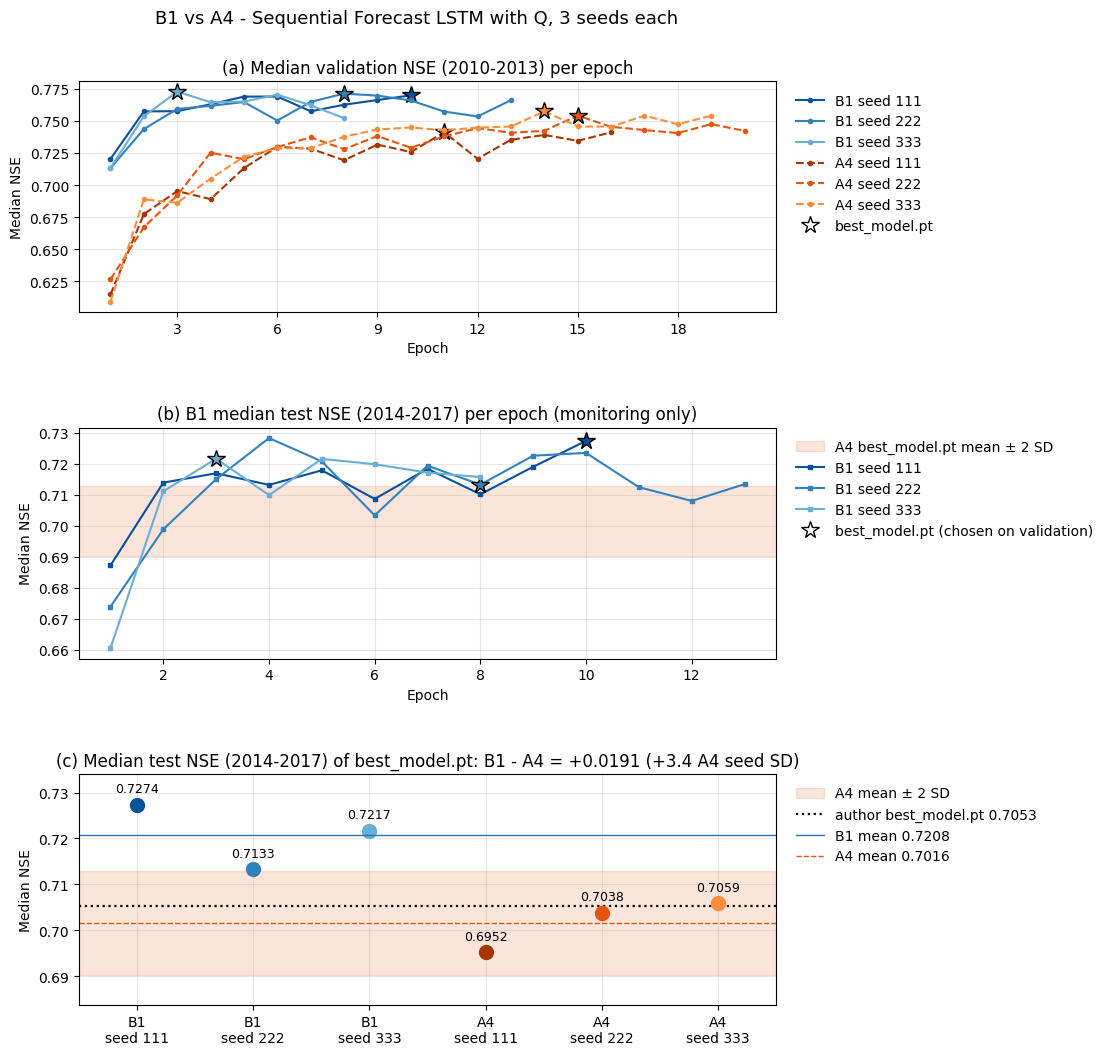

Hình: (a) NSE trung vị validation sau mỗi epoch của 6 run (B1 nét liền xanh, A4 nét đứt cam); ngôi sao là epoch lưu best_model.pt (B1 10, 8, 3; A4 11, 15, 14). (b) NSE trung vị test theo epoch của 3 hạt giống B1, chỉ để theo dõi (không dùng để chọn); epoch test cao nhất là 10 (seed 111), 4 (seed 222), 3 (seed 333), chênh so với best_model.pt 0.0000, 0.0150, 0.0000; dải cam là trung bình ± 2 độ lệch chuẩn của 3 hạt giống A4. (c) NSE trung vị test của best_model.pt: B1 trung bình 0.7208, A4 0.7016, tác giả 0.7053; khoảng 3 hạt giống hai bước không chồng nhau.


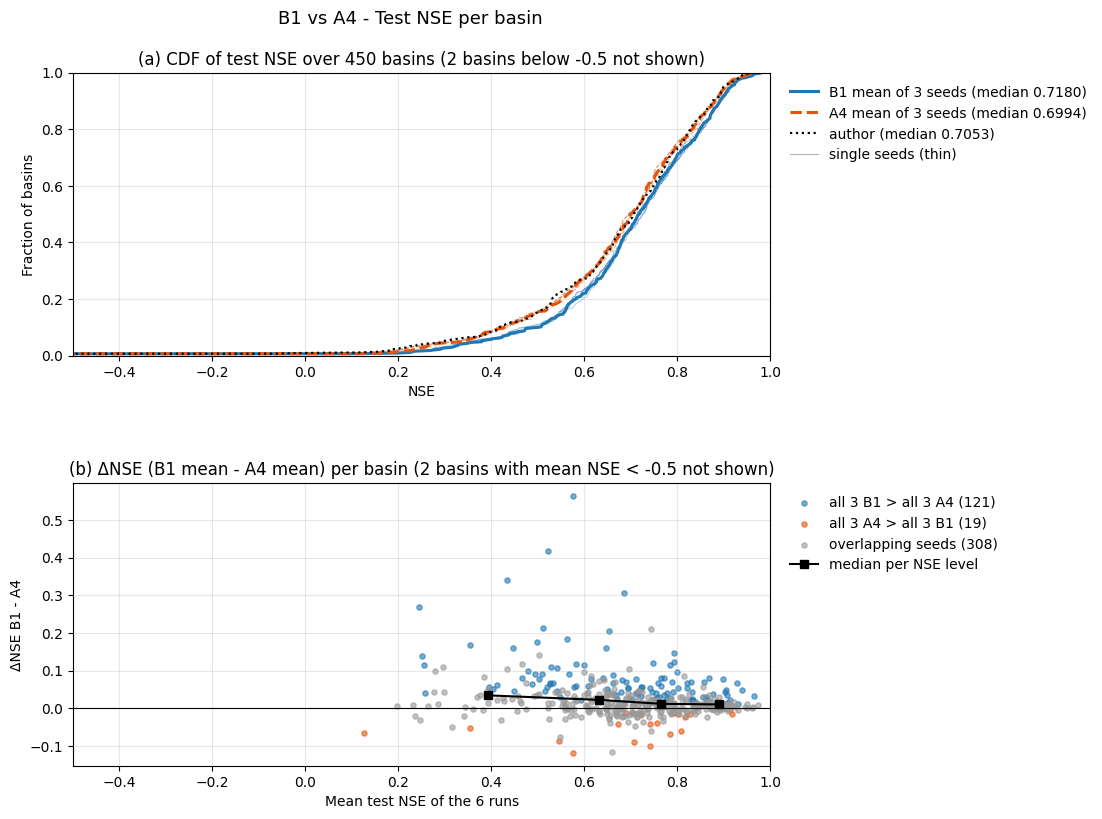

Hình: (a) Hàm phân phối tích lũy NSE test theo lưu vực: đường đậm là trung bình 3 hạt giống mỗi bước, đường mảnh là từng hạt giống, nét chấm là tác giả; đường càng lệch phải càng tốt. 2 lưu vực có NSE dưới -0.5 ở ít nhất một mô hình nằm ngoài trục (742, 758). (b) Mỗi chấm là một lưu vực: trục ngang NSE trung bình 6 run, trục dọc ΔNSE = trung bình B1 - trung bình A4; xanh là lưu vực cả 3 hạt giống B1 cao hơn cả 3 hạt giống A4 (121 lưu vực), cam là ngược lại (19); nếu hai bước chỉ khác nhau do hạt giống thì mỗi nhóm khoảng 5% = 22 lưu vực. Trung vị ΔNSE theo mức NSE từ thấp tới cao: +0.0340, +0.0220, +0.0115, +0.0099.
=> Đã lưu B1_Compare.png, B1_BasinDelta.png vào /kaggle/working/b1_compare - chạy Phần 5.


In [4]:
# %% Phần 4 - Hình
# B1_Compare.png - (a) NSE validation theo epoch của 6 run, (b) NSE test theo epoch của 3 hạt giống B1 (chỉ theo dõi, đọc từ
# environment.json "test_nse_median_per_epoch" do Phần 7 notebook huấn luyện ghi), (c) NSE trung vị test 6 run và tác giả.
# B1_BasinDelta.png - (a) CDF NSE test theo lưu vực, (b) ΔNSE B1 - A4 theo NSE trung bình 6 run của lưu vực.
# Hình từng hạt giống (loss, NSE theo epoch) đã có ở B1_EpochCurve_Seed{N}.png của notebook huấn luyện => ở đây chỉ vẽ gộp.
# Chữ trong hình tiếng Anh, chú giải đặt ngoài vùng vẽ, chú thích tiếng Việt in ngay dưới hình.
import matplotlib.pyplot as plt

RUN_COLORS = {("B1", 111): "#08519c", ("B1", 222): "#3182bd", ("B1", 333): "#6baed6",
              ("A4", 111): "#a63603", ("A4", 222): "#e6550d", ("A4", 333): "#fd8d3c"}
STEP_COLORS = {"B1": "#1f77b4", "A4": "#e6550d"}
STEP_LS = {"B1": "-", "A4": "--"}
AUTHOR_STYLE = {"color": "black", "ls": ":", "lw": 1.6}
NSE_XLIM = (-0.5, 1.0)  # NSE âm sâu chỉ ở vài lưu vực qmax gần như hằng số => ghi số lưu vực bị cắt
BAND_Z = 2              # dải trung bình ± 2 độ lệch chuẩn hạt giống A4
LEGEND = {"loc": "upper left", "bbox_to_anchor": (1.01, 1), "frameon": False}


def caption(text):
    print(f"Hình: {text}")


def save(fig, name):
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


def period_years(name):
    # Thư viện ghi ngày dd/mm/YYYY, một giá trị hoặc danh sách nhiều đoạn (utils/config.py) => năm đầu - năm cuối.
    start, end = cfg0[f"{name}_start_date"], cfg0[f"{name}_end_date"]
    start, end = (start[0] if isinstance(start, list) else start), (end[-1] if isinstance(end, list) else end)
    return f"{str(start)[-4:]}-{str(end)[-4:]}"


VAL_YEARS, TEST_YEARS = period_years("validation"), period_years("test")
TEST_CURVES = {s: pd.Series({int(e): v for e, v in ENVS["B1", s]["summary"]["test_nse_median_per_epoch"].items()}).sort_index()
               for s in SEEDS}
gap = {s: abs(TEST_CURVES[s][SUMMARY["B1", s]["saved_epoch"]] - SUMMARY["B1", s]["test_nse_median_best_model"]) for s in SEEDS}
if max(gap.values()) > 1e-6 or any(list(TEST_CURVES[s].index) != list(range(1, SUMMARY["B1", s]["n_epochs"] + 1)) for s in SEEDS):
    raise RuntimeError(f"NSE test theo epoch không khớp best_model.pt hoặc thiếu epoch: {gap}")

# Hình 1 - quá trình huấn luyện và NSE trung vị test
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 12), gridspec_kw={"hspace": 0.5})
for st, s in RUNS:
    c, e = VAL_CURVES[st, s], SUMMARY[st, s]["saved_epoch"]
    ax1.plot(c["epoch"], c[VAL_COL], marker="o", ms=3, ls=STEP_LS[st], color=RUN_COLORS[st, s], label=f"{st} seed {s}")
    ax1.plot(e, c.loc[c["epoch"] == e, VAL_COL].iloc[0], marker="*", ms=13, color=RUN_COLORS[st, s], mec="black", ls="none")
ax1.plot([], [], marker="*", ms=13, color="white", mec="black", ls="none", label="best_model.pt")
ax1.set(title=f"(a) Median validation NSE ({VAL_YEARS}) per epoch", xlabel="Epoch", ylabel="Median NSE")

t = STATS.set_index("chỉ số").loc["NSE trung vị test"]
a4_band = (t["A4 trung bình"] - BAND_Z * t["A4 độ lệch chuẩn"], t["A4 trung bình"] + BAND_Z * t["A4 độ lệch chuẩn"])
ax2.axhspan(*a4_band, color=STEP_COLORS["A4"], alpha=0.15, label=f"A4 best_model.pt mean ± {BAND_Z} SD")
for s in SEEDS:
    c, e = TEST_CURVES[s], SUMMARY["B1", s]["saved_epoch"]
    ax2.plot(c.index, c.values, marker="s", ms=3, color=RUN_COLORS["B1", s], label=f"B1 seed {s}")
    ax2.plot(e, c[e], marker="*", ms=13, color=RUN_COLORS["B1", s], mec="black", ls="none")
ax2.plot([], [], marker="*", ms=13, color="white", mec="black", ls="none", label="best_model.pt (chosen on validation)")
ax2.set(title=f"(b) B1 median test NSE ({TEST_YEARS}) per epoch (monitoring only)", xlabel="Epoch", ylabel="Median NSE")

ax3.axhspan(*a4_band, color=STEP_COLORS["A4"], alpha=0.15, label=f"A4 mean ± {BAND_Z} SD")
ax3.axhline(AUTHOR_NSE, **AUTHOR_STYLE, label=f"author best_model.pt {AUTHOR_NSE:.4f}")
for i, (st, s) in enumerate(RUNS):
    v = float(METRICS[st, s]["NSE"].median())
    ax3.plot(i, v, "o", ms=10, color=RUN_COLORS[st, s])
    ax3.annotate(f"{v:.4f}", (i, v), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
for st in STEPS:
    ax3.axhline(t[f"{st} trung bình"], color=STEP_COLORS[st], ls=STEP_LS[st], lw=1,
                label=f"{st} mean {t[f'{st} trung bình']:.4f}")
ax3.set(title=f"(c) Median test NSE ({TEST_YEARS}) of best_model.pt: B1 - A4 = {t['B1 - A4']:+.4f} "
              f"({t['(B1 - A4) / độ lệch chuẩn A4']:+.1f} A4 seed SD)",
        xticks=range(len(RUNS)), xticklabels=[f"{st}\nseed {s}" for st, s in RUNS], xlim=(-0.5, len(RUNS) - 0.5),
        ylabel="Median NSE")
ax3.margins(y=0.18)  # chừa chỗ cho số ghi trên chấm
for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
for ax in (ax1, ax2, ax3):
    ax.grid(alpha=0.3)
    ax.legend(**LEGEND)
fig.suptitle("B1 vs A4 - Sequential Forecast LSTM with Q, 3 seeds each", fontsize=13, y=0.94)
save(fig, "B1_Compare.png")
peak = {s: int(TEST_CURVES[s].idxmax()) for s in SEEDS}
caption(f"(a) NSE trung vị validation sau mỗi epoch của 6 run (B1 nét liền xanh, A4 nét đứt cam); ngôi sao là epoch lưu "
        f"best_model.pt (B1 {', '.join(str(SUMMARY['B1', s]['saved_epoch']) for s in SEEDS)}; A4 "
        f"{', '.join(str(SUMMARY['A4', s]['saved_epoch']) for s in SEEDS)}). (b) NSE trung vị test theo epoch của 3 hạt giống B1, chỉ để theo dõi (không dùng để chọn); epoch "
        f"test cao nhất là {', '.join(f'{peak[s]} (seed {s})' for s in SEEDS)}, chênh so với best_model.pt "
        f"{', '.join(f'{TEST_CURVES[s].max() - TEST_CURVES[s][SUMMARY['B1', s]['saved_epoch']]:.4f}' for s in SEEDS)}; "
        f"dải cam là trung bình ± {BAND_Z} độ lệch chuẩn của 3 hạt giống A4. (c) NSE trung vị test của best_model.pt: "
        f"B1 trung bình {t['B1 trung bình']:.4f}, A4 {t['A4 trung bình']:.4f}, tác giả {AUTHOR_NSE:.4f}; khoảng 3 hạt giống "
        f"hai bước {'chồng nhau' if t['khoảng 2 bước chồng nhau'] == 'có' else 'không chồng nhau'}.")

# Hình 2 - phân phối NSE theo lưu vực và ΔNSE từng lưu vực
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 9), gridspec_kw={"hspace": 0.45})
for st, s in RUNS:
    v = np.sort(BASIN[f"{st} {s}"].to_numpy())
    ax1.plot(v, np.arange(1, len(v) + 1) / len(v), color=RUN_COLORS[st, s], lw=0.8, alpha=0.5, ls=STEP_LS[st])
for st in STEPS:
    v = np.sort(BASIN[f"{st} trung bình"].to_numpy())
    ax1.plot(v, np.arange(1, len(v) + 1) / len(v), color=STEP_COLORS[st], lw=2.2, ls=STEP_LS[st],
             label=f"{st} mean of 3 seeds (median {np.median(v):.4f})")
v = np.sort(BASIN["tác giả"].to_numpy())
ax1.plot(v, np.arange(1, len(v) + 1) / len(v), **AUTHOR_STYLE, label=f"author (median {np.median(v):.4f})")
ax1.plot([], [], color="grey", lw=0.8, alpha=0.6, label="single seeds (thin)")
all_cols = COLS["B1"] + COLS["A4"] + ["tác giả"]
out_ids = list(BASIN.index[BASIN[all_cols].min(axis=1) < NSE_XLIM[0]])
ax1.set(title=f"(a) CDF of test NSE over {len(BASIN)} basins ({len(out_ids)} basins below {NSE_XLIM[0]:g} not shown)",
        xlabel="NSE", ylabel="Fraction of basins", xlim=NSE_XLIM, ylim=(0, 1))

mean6 = BASIN[COLS["B1"] + COLS["A4"]].mean(axis=1)
shown = BASIN[mean6 >= NSE_XLIM[0]]
groups = {"all 3 B1 > all 3 A4": shown["cả 3 B1 > cả 3 A4"], "all 3 A4 > all 3 B1": shown["cả 3 A4 > cả 3 B1"]}
groups["overlapping seeds"] = ~(groups["all 3 B1 > all 3 A4"] | groups["all 3 A4 > all 3 B1"])
for (name, mask), color in zip(groups.items(), [STEP_COLORS["B1"], STEP_COLORS["A4"], "#999999"]):
    ax2.scatter(mean6[shown.index][mask], shown.loc[mask, "ΔNSE B1 - A4"], s=14, alpha=0.6, color=color,
                label=f"{name} ({int(mask.sum())})")
lvl = shown.assign(m=mean6[shown.index]).groupby("mức NSE (trung bình 6 run)", observed=True).agg(
    x=("m", "median"), y=("ΔNSE B1 - A4", "median"))
ax2.plot(lvl["x"], lvl["y"], "s-", color="black", ms=6, label="median per NSE level")
ax2.axhline(0, color="black", lw=0.8)
ax2.set(title=f"(b) ΔNSE (B1 mean - A4 mean) per basin ({len(BASIN) - len(shown)} basins with mean NSE "
              f"< {NSE_XLIM[0]:g} not shown)", xlabel="Mean test NSE of the 6 runs", ylabel="ΔNSE B1 - A4",
        xlim=NSE_XLIM)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.legend(**LEGEND)
fig.suptitle("B1 vs A4 - Test NSE per basin", fontsize=13, y=0.95)
save(fig, "B1_BasinDelta.png")
caption(f"(a) Hàm phân phối tích lũy NSE test theo lưu vực: đường đậm là trung bình 3 hạt giống mỗi bước, đường mảnh là "
        f"từng hạt giống, nét chấm là tác giả; đường càng lệch phải càng tốt. {len(out_ids)} lưu vực có NSE dưới "
        f"{NSE_XLIM[0]:g} ở ít nhất một mô hình nằm ngoài trục ({', '.join(out_ids) or '-'}). (b) Mỗi chấm là một lưu vực: "
        f"trục ngang NSE trung bình 6 run, trục dọc ΔNSE = trung bình B1 - trung bình A4; xanh là lưu vực cả 3 hạt giống B1 "
        f"cao hơn cả 3 hạt giống A4 ({int(BASIN['cả 3 B1 > cả 3 A4'].sum())} lưu vực), cam là ngược lại "
        f"({int(BASIN['cả 3 A4 > cả 3 B1'].sum())}); nếu hai bước chỉ khác nhau do hạt giống thì mỗi nhóm khoảng "
        f"{P_ALL3:.0%} = {P_ALL3 * len(BASIN):.0f} lưu vực. Trung vị ΔNSE theo mức NSE từ thấp tới cao: "
        f"{', '.join(f'{v:+.4f}' for v in lvl['y'])}.")
print("=> Đã lưu B1_Compare.png, B1_BasinDelta.png vào", OUT_DIR, "- chạy Phần 5.")


# Phần 5 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
 Mỗi hạt giống B1 một tệp SeqLSTM_Q_B1_seed{N}_test_S0_lead1.npz theo hợp đồng ở Workspace/06_Evaluation/
 01_Evaluation_LamaHCEExt.md Mục 7, để bộ đánh giá đọc bằng --extra-contract; A4 đã có NPZ từ 04_A4_LamaHCEExt_Compare.
 Cùng mã Phần 5 của A4 Compare (đã chạy chính thức ở Version 2): sim thô lấy từ test_results.p (["1D"]["xr"]["qmax_sim"],
 time_step = 0, chưa chặn âm - tester.py dòng 319-322 chỉ chặn âm khi tính chỉ số), chặn âm theo clip_targets_to_zero của
 config.yml. B1 vẫn dự báo qmax (target_variables = ["qmax"], notebook huấn luyện Phần 2) nên tên biến như A4. obs,
 persistence, diện tích, thứ tự ID lấy nguyên từ ngữ cảnh A3 vì bộ đánh giá đòi bằng nhau từng bit (check_same_context).
 Kiểm lại: (1) đọc ngược theo điều kiện của read_contract và check_same_context; (2) NSE từng lưu vực tính lại khớp
 test_metrics.csv của thư viện; (3) obs riêng của run trùng mặt nạ và giá trị với obs A3.

In [5]:
# %% Phần 5 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
# Mỗi hạt giống B1 một tệp SeqLSTM_Q_B1_seed{N}_test_S0_lead1.npz theo hợp đồng ở Workspace/06_Evaluation/
# 01_Evaluation_LamaHCEExt.md Mục 7, để bộ đánh giá đọc bằng --extra-contract; A4 đã có NPZ từ 04_A4_LamaHCEExt_Compare.
# Cùng mã Phần 5 của A4 Compare (đã chạy chính thức ở Version 2): sim thô lấy từ test_results.p (["1D"]["xr"]["qmax_sim"],
# time_step = 0, chưa chặn âm - tester.py dòng 319-322 chỉ chặn âm khi tính chỉ số), chặn âm theo clip_targets_to_zero của
# config.yml. B1 vẫn dự báo qmax (target_variables = ["qmax"], notebook huấn luyện Phần 2) nên tên biến như A4. obs,
# persistence, diện tích, thứ tự ID lấy nguyên từ ngữ cảnh A3 vì bộ đánh giá đòi bằng nhau từng bit (check_same_context).
# Kiểm lại: (1) đọc ngược theo điều kiện của read_contract và check_same_context; (2) NSE từng lưu vực tính lại khớp
# test_metrics.csv của thư viện; (3) obs riêng của run trùng mặt nạ và giá trị với obs A3.
import pickle

CONTRACT_DIR = OUT_DIR / "contracts"
CONTRACT_DIR.mkdir(exist_ok=True)
CONTRACT_KEYS = ("run", "period", "scenario", "lead", "forecast_horizon", "seed", "unit", "config_sha256",
                 "library_commit", "clip_to_zero")
NSE_TOL = 1e-5  # NSE tính lại (float64) so với test_metrics.csv của thư viện
TEST_DATES = pd.date_range(pd.to_datetime(str(cfg0["test_start_date"]), dayfirst=True),
                           pd.to_datetime(str(cfg0["test_end_date"]), dayfirst=True))


def basin_id(value):
    return str(int(str(value).strip()))


def contract_name(seed):
    return f"SeqLSTM_Q_B1_seed{seed}"


# (1) Ngữ cảnh A3 - như read_context của bộ đánh giá
with np.load(A3_PATHS["A3_persistence_predictions.npz"], allow_pickle=False) as d:
    CTX_DATES = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_IDS = tuple(basin_id(x) for x in d["basin_ids"])
    CTX_OBS = np.array(d["obs_source_mm_day"], dtype=float)
    CTX_PERS = np.array(d["persistence_qmax_mm_day"], dtype=float)
    src_ok = np.array_equal(d["source_dates"], d["dates"] - np.timedelta64(1, "D"))
with np.load(A3_PATHS["A3_Q_source_window.npz"], allow_pickle=False) as d:
    q_ids = tuple(basin_id(x) for x in d["basin_ids"])
    q_dates = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_AREA = np.array(d["area_gov_km2"], dtype=float)
    q = np.array(d["qmax_numeric_m3_s"], dtype=float)
q[q < 0] = np.nan
physical = q * 86.4 / CTX_AREA[None, :]
ctx_checks = [(f"Lịch A3 = kỳ test của config.yml ({TEST_DATES[0]:%Y-%m-%d}..{TEST_DATES[-1]:%Y-%m-%d})",
               CTX_DATES.equals(TEST_DATES.as_unit("ns"))),
              ("Ngày nguồn persistence = ngày đích - 1", src_ok),
              ("ID nguồn Q trùng ID persistence", q_ids == CTX_IDS),
              ("Lịch nguồn Q bắt đầu trước kỳ test 1 ngày",
               q_dates.equals(pd.date_range(TEST_DATES[0] - pd.Timedelta(days=1), TEST_DATES[-1]).as_unit("ns"))),
              ("obs, persistence khớp Q gốc / diện tích",
               np.allclose(CTX_OBS, physical[1:], rtol=1e-12, atol=1e-12, equal_nan=True)
               and np.allclose(CTX_PERS, physical[:-1], rtol=1e-12, atol=1e-12, equal_nan=True)),
              ("Đủ 451 ID", len(CTX_IDS) == 451)]
show(f"Ngữ cảnh A3 ({len(CTX_DATES)} ngày x {len(CTX_IDS)} lưu vực)",
     pd.DataFrame([{"mục": a, "đạt": "ĐẠT" if b else "KHÔNG"} for a, b in ctx_checks]))
if not all(b for _, b in ctx_checks):
    raise RuntimeError(f"Phần 5 CHƯA đạt: ngữ cảnh A3 sai - kiểm Input A3 Version {A3_VERSION}")


def check_contract(path):
    # Các điều kiện của read_contract + check_same_context với ngữ cảnh A3; trả danh sách lỗi.
    errs = []
    with np.load(path, allow_pickle=False) as d:
        meta = json.loads(str(d["metadata_json"].item()))
        if any(k not in meta for k in CONTRACT_KEYS) or meta.get("unit") != "mm/day_area_gov":
            errs.append("thiếu metadata hoặc sai đơn vị")
        if not isinstance(meta.get("clip_to_zero"), bool):
            errs.append("clip_to_zero không phải bool")
        lead, hz = meta.get("lead"), meta.get("forecast_horizon")
        if not (isinstance(lead, int) and isinstance(hz, int) and 1 <= lead <= hz <= 7):
            errs.append("sai lead/forecast_horizon")
        dates = np.array(d["dates"], dtype="datetime64[D]")
        if (not np.array_equal(d["origin_dates"], dates - np.timedelta64(lead - 1, "D"))
                or not np.array_equal(d["persistence_source_dates"], dates - np.timedelta64(lead, "D"))):
            errs.append("sai origin/persistence_source_dates")
        raw, sim = np.array(d["sim_raw_mm_day"], dtype=float), np.array(d["sim_mm_day"], dtype=float)
        if not np.array_equal(sim, np.maximum(raw, 0) if meta.get("clip_to_zero") else raw, equal_nan=True):
            errs.append("sim khác chính sách chặn âm")
        if np.isinf(sim).any() or np.isinf(raw).any() or sim.shape != (len(CTX_DATES), len(CTX_IDS)):
            errs.append("sim sai kích thước hoặc có vô cực")
        if (not pd.DatetimeIndex(dates).as_unit("ns").equals(CTX_DATES)
                or tuple(basin_id(x) for x in d["basin_ids"]) != CTX_IDS
                or not np.array_equal(d["area_gov_km2"], CTX_AREA)):
            errs.append("khác lịch, ID hoặc diện tích ngữ cảnh A3")
        for k, ref in (("obs_mm_day", CTX_OBS), ("persistence_mm_day", CTX_PERS)):
            if not np.array_equal(d[k], ref, equal_nan=True):
                errs.append(f"{k} khác ngữ cảnh A3")
    return errs


def nse_basin(obs, sim):
    ok = np.isfinite(obs) & np.isfinite(sim)
    o, s = obs[ok], sim[ok]
    return 1 - np.sum((s - o) ** 2) / np.sum((o - o.mean()) ** 2) if len(o) > 1 else np.nan


# (2) Dựng và kiểm từng hạt giống B1
rows, CONTRACT_PATHS = [], {}
target = CTX_DATES.to_numpy().astype("datetime64[D]")
for s in SEEDS:
    run_dir = ROOTS["B1", s] / ENVS["B1", s]["run_dir"]
    cfg_path = run_dir / "config.yml"
    clip = CFGS["B1", s].get("clip_targets_to_zero", []) or []
    clip = [clip] if isinstance(clip, str) else clip
    # test_results.p là pickle do chính notebook huấn luyện ghi, sha256 đã khớp manifest ở Phần 1 => nạp được.
    with (run_dir / "test" / "best_model" / "test_results.p").open("rb") as fp:
        saved = pickle.load(fp)
    keys = {basin_id(k): k for k in saved}
    if len(keys) != len(saved) or set(keys) != set(CTX_IDS):
        raise RuntimeError(f"Hạt giống {s}: ID trong test_results.p thiếu, thừa hoặc trùng")
    native, raw = np.full_like(CTX_OBS, np.nan), np.full_like(CTX_OBS, np.nan)
    for j, b in enumerate(CTX_IDS):
        xr_ = saved[keys[b]]["1D"]["xr"]
        if (not np.array_equal(xr_["time_step"].values, [0])
                or not pd.DatetimeIndex(xr_["date"].values).as_unit("ns").equals(CTX_DATES)):
            raise RuntimeError(f"Hạt giống {s}, lưu vực {b}: time_step khác [0] hoặc lịch khác kỳ test")
        native[:, j] = xr_["qmax_obs"].transpose("date", "time_step").values[:, 0]
        raw[:, j] = xr_["qmax_sim"].transpose("date", "time_step").values[:, 0]
    sim = np.maximum(raw, 0) if "qmax" in clip else raw.copy()
    meta = {"run": contract_name(s), "period": "test", "scenario": "S0", "lead": 1, "forecast_horizon": 1, "seed": s,
            "unit": "mm/day_area_gov", "config_sha256": sha256(cfg_path),
            "library_commit": ENVS["B1", s]["neuralhydrology_commit"], "clip_to_zero": "qmax" in clip,
            "selected_epoch": SUMMARY["B1", s]["saved_epoch"],
            "source": f"{STEPS['B1']['notebook'].format(s)} Version {STEPS['B1']['versions'][s]}, "
                      f"{ENVS['B1', s]['run_dir']}/test/best_model/test_results.p"}
    path = CONTRACT_DIR / f"{contract_name(s)}_test_S0_lead1.npz"
    np.savez_compressed(path, dates=target, origin_dates=target, persistence_source_dates=target - np.timedelta64(1, "D"),
                        basin_ids=np.array(CTX_IDS), area_gov_km2=CTX_AREA, obs_mm_day=CTX_OBS,
                        persistence_mm_day=CTX_PERS, sim_raw_mm_day=raw, sim_mm_day=sim, metadata_json=json.dumps(meta))
    CONTRACT_PATHS[s] = path

    # Kiểm: hợp đồng, NSE so với thư viện, obs riêng của run so với A3
    errs = check_contract(path)
    lib = METRICS["B1", s]["NSE"].reindex(list(CTX_IDS)).to_numpy(dtype=float)
    mine = np.array([nse_basin(native[:, j], sim[:, j]) for j in range(len(CTX_IDS))])
    both = np.isfinite(lib) & np.isfinite(mine)
    nse_diff = float(np.max(np.abs(lib[both] - mine[both]))) if both.any() else np.nan
    nan_same = np.array_equal(np.isfinite(lib), np.isfinite(mine))
    mask_same = np.array_equal(np.isfinite(native), np.isfinite(CTX_OBS))
    both_obs = np.isfinite(native) & np.isfinite(CTX_OBS)
    rows.append({"hạt giống": s, "tệp": path.name, "MB": path.stat().st_size / 1e6,
                 "clip_to_zero": meta["clip_to_zero"], "dự báo âm trước chặn": int((raw < 0).sum()),
                 "ngày-lưu vực có sim": int(np.isfinite(sim).sum()), "lỗi hợp đồng": "; ".join(errs) or "-",
                 "max |ΔNSE| so với thư viện": nse_diff, "NaN NSE trùng thư viện": nan_same,
                 "mặt nạ obs trùng A3": mask_same,
                 "max |obs run - obs A3|": float(np.max(np.abs(native[both_obs] - CTX_OBS[both_obs]))),
                 "đạt": not errs and nse_diff <= NSE_TOL and nan_same and mask_same})
CONTRACT_TABLE = pd.DataFrame(rows)
show("Hợp đồng NPZ cho bộ đánh giá (kiểm đọc ngược và NSE tính lại)", CONTRACT_TABLE, digits=6)
if not CONTRACT_TABLE["đạt"].all():
    raise RuntimeError(f"Phần 5 CHƯA đạt (cột 'đạt' = False ở trên; ngưỡng NSE {NSE_TOL})")
print(f"=> Đạt. 3 tệp ở {CONTRACT_DIR}; bộ đánh giá đọc bằng --extra-contract. Chạy Phần 6.")


mục,đạt
Lịch A3 = kỳ test của config.yml (2014-01-01..2017-12-31),ĐẠT
Ngày nguồn persistence = ngày đích - 1,ĐẠT
ID nguồn Q trùng ID persistence,ĐẠT
Lịch nguồn Q bắt đầu trước kỳ test 1 ngày,ĐẠT
"obs, persistence khớp Q gốc / diện tích",ĐẠT
Đủ 451 ID,ĐẠT


hạt giống,tệp,MB,clip_to_zero,dự báo âm trước chặn,ngày-lưu vực có sim,lỗi hợp đồng,max |ΔNSE| so với thư viện,NaN NSE trùng thư viện,mặt nạ obs trùng A3,max |obs run - obs A3|,đạt
111,SeqLSTM_Q_B1_seed111_test_S0_lead1.npz,9.964364,True,348,652644,-,0.000000,True,True,0.000011,True
222,SeqLSTM_Q_B1_seed222_test_S0_lead1.npz,9.982400,True,1765,652644,-,0.000001,True,True,0.000011,True
333,SeqLSTM_Q_B1_seed333_test_S0_lead1.npz,9.978169,True,4454,652644,-,0.000000,True,True,0.000011,True


=> Đạt. 3 tệp ở /kaggle/working/b1_compare/contracts; bộ đánh giá đọc bằng --extra-contract. Chạy Phần 6.


# Phần 6 - Lưu kết quả và môi trường
 Lưu 2 bảng của Phần 2, tóm tắt B1 (b1_summary.json - số liệu dùng cho báo cáo), environment.json (Input đã gắn, phiên bản
 notebook nguồn, thư viện) và manifest.csv (mọi tệp trong b1_compare kèm sha256 để bước sau kiểm khi gắn Output này làm
 Input). Quy tắc lưu mô hình đã lưu ở Phần 2, bảng từng lưu vực và kiểm định ghép cặp ở Phần 3, hình ở Phần 4, NPZ ở Phần 5.

In [6]:
# %% Phần 6 - Lưu kết quả và môi trường
# Lưu 2 bảng của Phần 2, tóm tắt B1 (b1_summary.json - số liệu dùng cho báo cáo), environment.json (Input đã gắn, phiên bản
# notebook nguồn, thư viện) và manifest.csv (mọi tệp trong b1_compare kèm sha256 để bước sau kiểm khi gắn Output này làm
# Input). Quy tắc lưu mô hình đã lưu ở Phần 2, bảng từng lưu vực và kiểm định ghép cặp ở Phần 3, hình ở Phần 4, NPZ ở Phần 5.
SEED_TABLE.to_csv(OUT_DIR / "B1_seed_table.csv", index=False)
STATS.to_csv(OUT_DIR / "B1_seed_stats.csv", index=False)


def stat(metric, col):
    return float(STATS.set_index("chỉ số").loc[metric, col])


main = PAIRED.iloc[0]
B1_SUMMARY = {
    "author_test_nse_median": AUTHOR_NSE,
    "test_nse_median": {f"{st} {s}": float(METRICS[st, s]["NSE"].median()) for st, s in RUNS},
    **{f"{key}_{st}": {"mean": stat(metric, f"{st} trung bình"), "sd": stat(metric, f"{st} độ lệch chuẩn")}
       for key, metric in [("test_nse", "NSE trung vị test"), ("val_nse", "NSE trung vị validation"),
                           ("test_kge", "KGE trung vị test")] for st in STEPS},
    "b1_minus_a4_in_a4_sd": {metric: stat(metric, "(B1 - A4) / độ lệch chuẩn A4")
                             for metric in ["NSE trung vị test", "NSE trung vị validation", "KGE trung vị test"]},
    "saved_epoch": {f"{st} {s}": SUMMARY[st, s]["saved_epoch"] for st, s in RUNS},
    "n_epochs": {f"{st} {s}": SUMMARY[st, s]["n_epochs"] for st, s in RUNS},
    "train_hours": {f"{st} {s}": SUMMARY[st, s]["train_hours"] for st, s in RUNS},
    "fix_changed_selected_epoch_b1": changed,
    "b1_test_peak_epoch": {s: peak[s] for s in SEEDS},
    "b1_test_peak_minus_selected": {s: float(TEST_CURVES[s].max() - TEST_CURVES[s][SUMMARY["B1", s]["saved_epoch"]])
                                    for s in SEEDS},
    "basins_compared": len(BASIN),
    "basin_delta_median": float(BASIN["ΔNSE B1 - A4"].median()),
    "basins_b1_better": int((BASIN["ΔNSE B1 - A4"] > 0).sum()),
    "basins_all3_b1_gt_a4": int(BASIN["cả 3 B1 > cả 3 A4"].sum()),
    "basins_all3_a4_gt_b1": int(BASIN["cả 3 A4 > cả 3 B1"].sum()),
    "exchangeable_probability_each_side": P_ALL3,
    "basin_delta_median_by_level": {str(k): float(v) for k, v in
                                    BASIN.groupby("mức NSE (trung bình 6 run)", observed=True)["ΔNSE B1 - A4"].median().items()},
    "basin_nse_sd_median": {st: float(BASIN[f"{st} độ lệch chuẩn"].median()) for st in STEPS},
    "main_test": {"median_diff": float(main["trung vị hiệu"]), "mean_diff": float(main["trung bình hiệu"]),
                  "cohens_dz": float(main["Cohen's dz"]), "p_holm": float(main["p Holm"])},
    "b1_seed_pair_p_holm": {f"{r['trái']} - {r['phải']}": float(r["p Holm"])
                            for _, r in PAIRED[PAIRED["họ"].str.startswith("(d)")].iterrows()},
    "negative_sim_before_clip": {int(r["hạt giống"]): int(r["dự báo âm trước chặn"]) for _, r in CONTRACT_TABLE.iterrows()},
    "contracts": {s: CONTRACT_PATHS[s].relative_to(WORK_DIR).as_posix() for s in SEEDS}}
(OUT_DIR / "b1_summary.json").write_text(json.dumps(B1_SUMMARY, ensure_ascii=False, indent=2), encoding="utf-8")

env = {"notebook": "02_B1_LamaHCEExt_Compare", "env": {k: str(v) for k, v in ENV.items()},
       "inputs": {"runs": {f"{st} {s}": {"notebook": STEPS[st]["notebook"].format(s), "version": STEPS[st]["versions"][s],
                                         "input_dir": short(ROOTS[st, s]), "run_dir": ENVS[st, s]["run_dir"],
                                         "neuralhydrology_commit": ENVS[st, s]["neuralhydrology_commit"]}
                           for st, s in RUNS},
                  "a3": {"notebook": "02_A3_LamaHCEExt_Benchmarks", "version": A3_VERSION,
                         "files": {n: {"path": short(p), "sha256": sha256(p)} for n, p in A3_PATHS.items()}},
                  "author_test_metrics": {"path": short(AUTHOR_METRICS_PATH), "sha256": sha256(AUTHOR_METRICS_PATH)}}}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
MANIFEST = pd.DataFrame([{"tệp": p.relative_to(OUT_DIR).as_posix(), "KB": p.stat().st_size / 1e3, "sha256": sha256(p)}
                         for p in files])
MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
show(f"Output trong {OUT_DIR.relative_to(WORK_DIR)}/ ({len(MANIFEST)} tệp, {MANIFEST['KB'].sum() / 1e3:.1f} MB)",
     MANIFEST.assign(sha256=MANIFEST["sha256"].str[:12]), digits=1)
expected = {"B1_seed_table.csv", "B1_seed_stats.csv", "B1_selection_rule.csv", "B1_basin_delta.csv", "B1_paired_tests.csv",
            "B1_Compare.png", "B1_BasinDelta.png", "b1_summary.json", "environment.json"} | {
            f"contracts/{CONTRACT_PATHS[s].name}" for s in SEEDS}
missing = sorted(expected - set(MANIFEST["tệp"]))
if missing:
    raise RuntimeError(f"Phần 6 CHƯA đạt: thiếu {missing}")
print("=> Xong. Tải 2 hình B1_Compare.png, B1_BasinDelta.png về Workspace/05_Training/02_B1_LamaHCEExt_Compare/Figures/; "
      "Output này (Save Version) gắn làm Input cho bộ đánh giá (--extra-contract với 3 tệp trong contracts/).")


tệp,KB,sha256
B1_BasinDelta.png,201.3,b16609a73607
B1_Compare.png,284.2,e87d0dbb1857
B1_basin_delta.csv,127.9,f1c2ad416f83
B1_paired_tests.csv,1.8,165e9bcff19b
B1_seed_stats.csv,0.9,07357b3dd0d8
B1_seed_table.csv,1.0,8cd299f9393f
B1_selection_rule.csv,0.8,c51483de58bf
b1_summary.json,2.8,bf85e11059dc
contracts/SeqLSTM_Q_B1_seed111_test_S0_lead1.npz,9964.4,0a14263e72b0
contracts/SeqLSTM_Q_B1_seed222_test_S0_lead1.npz,9982.4,302c9ac6cd9f


=> Xong. Tải 2 hình B1_Compare.png, B1_BasinDelta.png về Workspace/05_Training/02_B1_LamaHCEExt_Compare/Figures/; Output này (Save Version) gắn làm Input cho bộ đánh giá (--extra-contract với 3 tệp trong contracts/).
